# Product Recommendation System



## Objective

The objective of this project is to build a product recommendation system that suggests similar products based on the information and features of a selected product.

## 3. Import Libraries

In [9]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import seaborn as sns

## 4. Load Dataset

In [11]:
df=pd.read_csv(r"C:\Users\L\OneDrive\Desktop\Customer-Recommendation-System\data\product_recommendation_dataser.csv")

## 5. Data Cleaning and Organization

In [3]:
df.isnull().sum()

Product_Name    0
Category        0
Brand           0
Description     0
Price           0
Rating          0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_Name  49 non-null     str    
 1   Category      49 non-null     str    
 2   Brand         49 non-null     str    
 3   Description   49 non-null     str    
 4   Price         49 non-null     int64  
 5   Rating        49 non-null     float64
dtypes: float64(1), int64(1), str(4)
memory usage: 2.4 KB


In [7]:
df.describe()

,Price,Rating
count,49.000000,49.000000
mean,11909.204082,4.444898
std,19496.690370,0.137024
min,699.000000,4.200000
25%,1799.000000,4.400000
50%,3499.000000,4.400000
75%,8999.000000,4.500000
max,79999.000000,4.700000


## 6. Understanding the Dataset

df.shape

In [10]:
df.columns

Index(['Product_Name', 'Category', 'Brand', 'Description', 'Price', 'Rating'], dtype='str')

In [11]:
df.head()

,Product_Name,Category,Brand,Description,Price,Rating
0,Wireless Mouse,Computer Accessories,Logitech,Wireless optical mouse for laptops and desktops,899,4.4
1,Gaming Mouse,Computer Accessories,Logitech,High precision gaming mouse with adjustable DPI,1499,4.6
2,Bluetooth Keyboard,Computer Accessories,Logitech,Wireless Bluetooth keyboard for computers,1799,4.5
3,Mechanical Keyboard,Computer Accessories,Redragon,Mechanical gaming keyboard with RGB lighting,2499,4.7
4,Laptop Stand,Computer Accessories,Portronics,Adjustable aluminum laptop stand for desk use,1299,4.3


## 7. Exploratory Data Analysis

In [13]:
df["Category"].value_counts()

Category
Computer Accessories    7
Footwear                5
Clothing                5
Home Appliances         5
Audio                   4
Storage                 4
Computers               4
Bags                    3
Tablets                 3
Smartphones             3
Home & Office           3
Wearables               2
Lifestyle               1
Name: count, dtype: int64

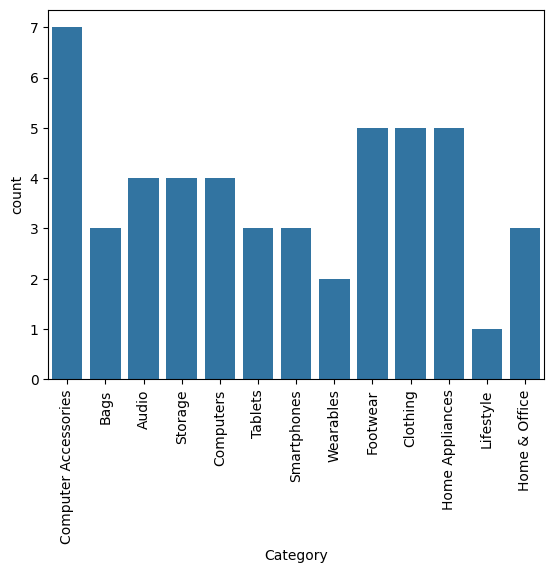

In [15]:
sns.countplot(data=df, x="Category")
plt.xticks(rotation=90)
plt.show()

## 8. Price Analysis

In [18]:
df["Price"].describe()

count       49.000000
mean     11909.204082
std      19496.690370
min        699.000000
25%       1799.000000
50%       3499.000000
75%       8999.000000
max      79999.000000
Name: Price, dtype: float64

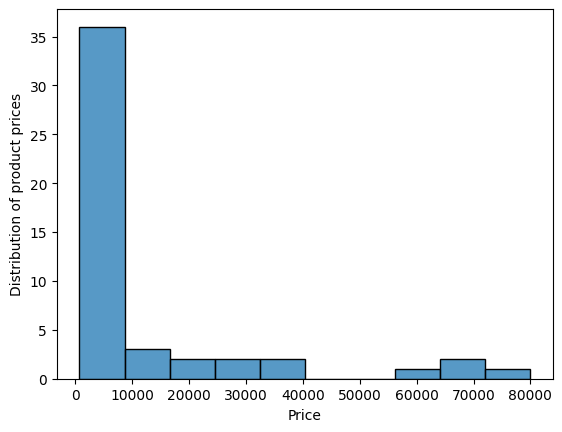

In [12]:
sns.histplot(data=df, x="Price", bins=10)
plt.xlabel("Price")
plt.ylabel("Distribution of product prices")
plt.show()

## 9. Rating Analysis

In [13]:
df["Rating"].describe()

count    49.000000
mean      4.444898
std       0.137024
min       4.200000
25%       4.400000
50%       4.400000
75%       4.500000
max       4.700000
Name: Rating, dtype: float64

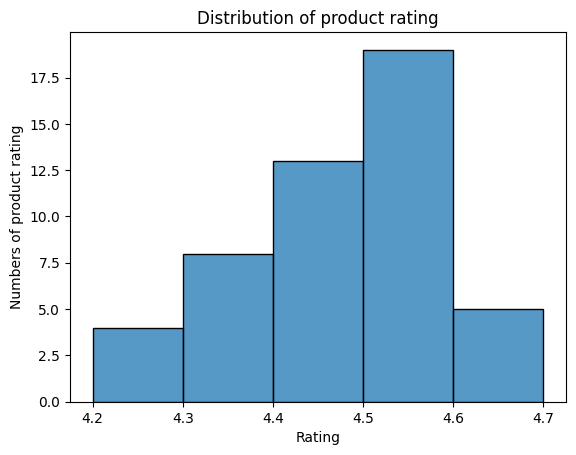

In [14]:
sns.histplot(data=df, x="Rating", bins=5)
plt.xlabel("Rating")
plt.ylabel("Numbers of product rating")
plt.title("Distribution of product rating")
plt.show()

## 10. Prepare Data for Recommendation

In [15]:
df["combined_features"] = (
    df["Category"] + " " +
    df["Brand"] + " " +
    df["Description"]
)

In [16]:
df[["Product_Name", "combined_features"]].head()

,Product_Name,combined_features
0,Wireless Mouse,Computer Accessories Logitech Wireless optical...
1,Gaming Mouse,Computer Accessories Logitech High precision g...
2,Bluetooth Keyboard,Computer Accessories Logitech Wireless Bluetoo...
3,Mechanical Keyboard,Computer Accessories Redragon Mechanical gamin...
4,Laptop Stand,Computer Accessories Portronics Adjustable alu...


## 11. Convert Text into Numerical Values using TF-IDF

In [18]:
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df["combined_features"])

## 12. Calculate Product Similarity using Cosine Similarity

In [20]:
similarity_matrix = cosine_similarity(tfidf_matrix)

## 13. Build the Recommendation Function

In [22]:
def recommend_products(product_name, num_recommendations=5):
    product_index = df[df["Product_Name"] == product_name].index[0]

    similarity_scores = similarity_matrix[product_index]

    similar_products = sorted(
        enumerate(similarity_scores),
        key=lambda x: x[1],
        reverse=True
    )

    recommendations = []

    for index, score in similar_products[1:num_recommendations + 1]:
        recommendations.append(df.iloc[index]["Product_Name"])

    return recommendations

## 14. Testing the Recommendation System

In [24]:
recommend_products("Wireless Mouse")

['Bluetooth Keyboard',
 'Gaming Mouse',
 'Webcam',
 'Laptop Stand',
 'Laptop Backpack']